
TRAIN folder exists: True
Sample files: ['cat.241.jpg', 'cat.3.jpg', 'dog.395.jpg', 'cat.224.jpg', 'cat.410.jpg', 'cat.347.jpg', 'cat.111.jpg', 'dog.360.jpg', 'cat.168.jpg', 'dog.228.jpg']

VAL folder exists: True
Sample files: ['dog.12011.jpg', 'cat.12038.jpg', 'dog.12041.jpg', 'dog.12077.jpg', 'dog.12024.jpg', 'dog.12040.jpg', 'cat.12027.jpg', 'dog.12043.jpg', 'dog.12036.jpg', 'cat.12076.jpg']

TEST folder exists: True
Sample files: ['26.jpg', '3.jpg', '80.jpg', '29.jpg', '35.jpg', '9.jpg', '18.jpg', '6.jpg', '49.jpg', '24.jpg']

Labeled training images: 1000
Training cats: 500
Training dogs: 500
Labeled validation images: 200
Validation cats: 100
Validation dogs: 100


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 53s 2s/step - accuracy: 0.4940 - loss: 0.7015 - val_accuracy: 0.5000 - val_loss: 0.6893
Epoch 2/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.5170 - loss: 0.6885 - val_accuracy: 0.5050 - val_loss: 0.6921
Epoch 3/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.5440 - loss: 0.6868 - val_accuracy: 0.6300 - val_loss: 0.6775
Epoch 4/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.6240 - loss: 0.6371 - val_accuracy: 0.6150 - val_loss: 0.6935
Epoch 5/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.6730 - loss: 0.6205 - val_accuracy: 0.6450 - val_loss: 0.6791
Epoch 6/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.7100 - loss: 0.5691 - val_accuracy: 0.6750 - val_loss: 0.6437
Epoch 7/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 62s 1s/step - accuracy: 0.7430 - loss: 0.5311 - val_accuracy: 0.6600 - val_loss: 0.6757
Epoch 8/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - accuracy: 0.7730 - loss: 0.4795 - val_accuracy: 0.6700 - val_loss:

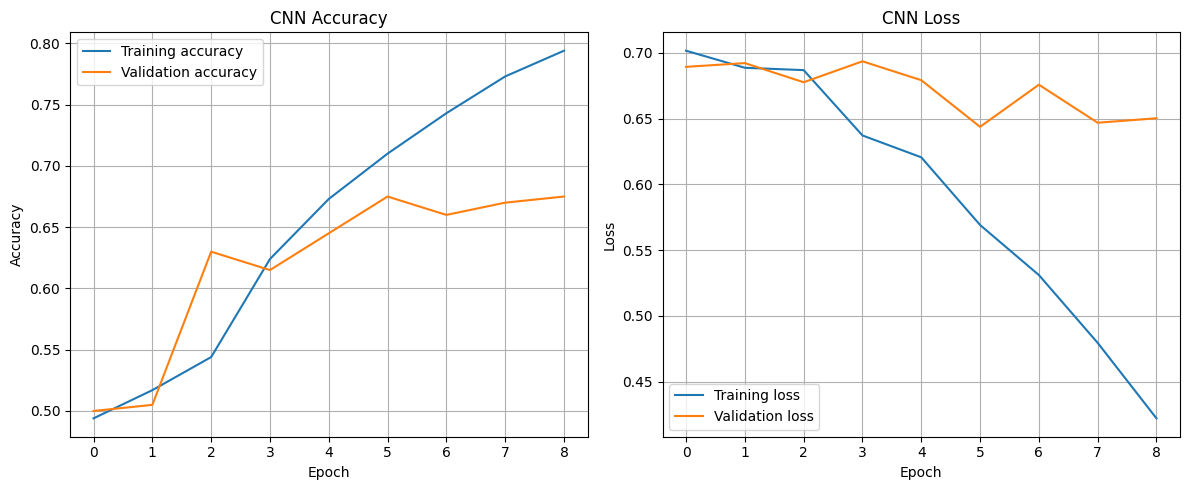

Model saved to /content/dog_cat_cnn_model.keras

Upload a cat or dog image for prediction.


In [ ]:

import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split

BASE_DIR = "/content/dogs_cats_data/dogs_vs_cats_subset"
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 15


for split in ["train", "val", "test"]:
    folder = os.path.join(BASE_DIR, split)
    print(f"\n{split.upper()} folder exists:", os.path.isdir(folder))

    if os.path.isdir(folder):
        print("Sample files:", os.listdir(folder)[:10])

train_dir = os.path.join(BASE_DIR, "train")
val_dir = os.path.join(BASE_DIR, "val")
test_dir = os.path.join(BASE_DIR, "test")


def get_labeled_images(folder):
    paths, labels = [], []

    for path in glob.glob(os.path.join(folder, "**", "*"), recursive=True):
        if not os.path.isfile(path):
            continue

        if not path.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        ):
            continue

        name = os.path.basename(path).lower()

        if name.startswith("cat"):
            label = 0
        elif name.startswith("dog"):
            label = 1
        else:
            continue

        try:
            with Image.open(path) as im:
                im.verify()
        except Exception:
            print("Skipping invalid image:", path)
            continue

        paths.append(path)
        labels.append(label)

    return np.array(paths), np.array(labels, dtype=np.int32)


train_paths, train_labels = get_labeled_images(train_dir)
val_paths, val_labels = get_labeled_images(val_dir)

print("\nLabeled training images:", len(train_paths))
print("Training cats:", np.sum(train_labels == 0))
print("Training dogs:", np.sum(train_labels == 1))
print("Labeled validation images:", len(val_paths))
print("Validation cats:", np.sum(val_labels == 0))
print("Validation dogs:", np.sum(val_labels == 1))


if len(val_paths) == 0:
    print("No labeled validation images found.")
    train_paths, val_paths, train_labels, val_labels = train_test_split(
        train_paths,
        train_labels,
        test_size=0.2,
        random_state=42,
        stratify=train_labels
    )

if len(train_paths) == 0 or len(val_paths) == 0:
    raise ValueError(
        "No labeled images found. Check the sample filenames printed above. "
        "The dataset may use a different naming convention."
    )


def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(
        img, channels=3, expand_animations=False
    )
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0

    return img, tf.cast(label, tf.float32)


def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)


model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop]
)


val_loss, val_accuracy = model.evaluate(val_ds, verbose=1)

print("\n========== RESULTS ==========")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


model.save("/content/dog_cat_cnn_model.keras")
print("Model saved to /content/dog_cat_cnn_model.keras")


from google.colab import files

def predict_animal(img_path):
    img = tf.keras.utils.load_img(
        img_path, target_size=IMG_SIZE
    )
    arr = tf.keras.utils.img_to_array(img) / 255.0
    arr = np.expand_dims(arr, axis=0)

    dog_probability = float(model.predict(arr, verbose=0)[0][0])

    if dog_probability >= 0.5:
        predicted_class = "Dog"
        confidence = dog_probability
    else:
        predicted_class = "Cat"
        confidence = 1.0 - dog_probability

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )
    plt.show()

    print("Predicted class:", predicted_class)
    print(f"Confidence: {confidence * 100:.2f}%")


print("\nUpload a cat or dog image for prediction.")
uploaded = files.upload()

for filename in uploaded.keys():
    predict_animal(filename)

print("\nProject completed!")
